# KNN sobre iris — notebook de verificación de ambiente

Objetivo: confirmar que tu ambiente (sea `.venv`, miniconda o uv) quedó bien montado.
Si las cinco celdas corren sin error, estás listo.

Tiempo esperado de ejecución: menos de 10 segundos en cualquier máquina razonable.

In [1]:
# 1. Imports. Si alguno falla, el ambiente no quedo bien.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

print(f"numpy        {np.__version__}")
print(f"pandas       {pd.__version__}")
import sklearn; print(f"scikit-learn {sklearn.__version__}")
import matplotlib; print(f"matplotlib   {matplotlib.__version__}")

numpy        2.5.4
pandas       3.0.6
scikit-learn 1.9.1
matplotlib   3.11.2


In [2]:
# 2. Cargar el dataset de iris. Son 150 flores, 4 variables, 3 especies.
X, y = load_iris(return_X_y=True, as_frame=True)
print(f"Shape de X: {X.shape}")
print(f"Clases: {sorted(y.unique())}")
X.head()

Shape de X: (150, 4)
Clases: [np.int64(0), np.int64(1), np.int64(2)]


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [3]:
# 3. Particion 70/30, estratificada por clase para que las tres especies queden representadas en train y test.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)
print(f"Train: {X_train.shape[0]} filas")
print(f"Test:  {X_test.shape[0]} filas")

Train: 105 filas
Test:  45 filas


In [4]:
# 4. Entrenar KNN con k=5 y evaluar.
modelo = KNeighborsClassifier(n_neighbors=5)
modelo.fit(X_train, y_train)
predicciones = modelo.predict(X_test)

print(f"Accuracy en test: {accuracy_score(y_test, predicciones):.3f}\n")
print(classification_report(y_test, predicciones, target_names=load_iris().target_names))

Accuracy en test: 0.978

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.94      1.00      0.97        15
   virginica       1.00      0.93      0.97        15

    accuracy                           0.98        45
   macro avg       0.98      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45



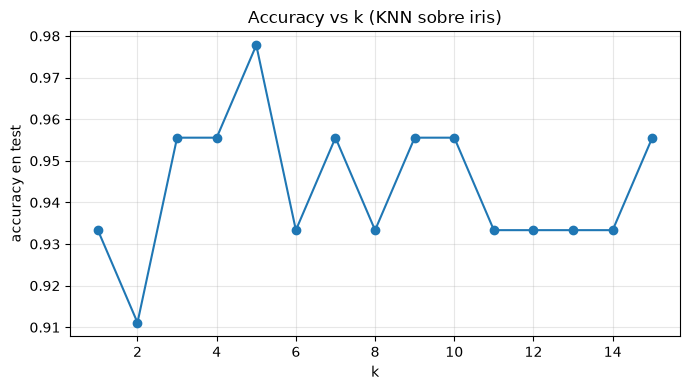

In [5]:
# 5. Barrer k de 1 a 15 y graficar accuracy. Si ves la curva, matplotlib tambien quedo bien.
resultados = []
for k in range(1, 16):
    m = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
    resultados.append({"k": k, "accuracy": m.score(X_test, y_test)})

df_k = pd.DataFrame(resultados).set_index("k")
ax = df_k.plot(marker="o", legend=False, figsize=(7, 4))
ax.set_title("Accuracy vs k (KNN sobre iris)")
ax.set_ylabel("accuracy en test")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Fin

Si llegaste hasta aquí, el ambiente está bien montado. Vuelve al [`README.md`](README.md) del tutorial y compara el tiempo que te tomó cada gestor contra la tabla de referencia.